In [1]:
import pandas as pd
import numpy as np
import datetime as dt

In [15]:
ips = pd.read_csv("../output_data/trig_and_bg_probs.csv", index_col=0, parse_dates=["time"])


In [19]:
ips

,latitude,longitude,time,magnitude,mc_current,mc_current_above_ref,mu,P_triggered,P_background,zeta_plus_1
target_id,,,,,,,,,,
8127,42.436660,-119.380154,1981-01-02 21:43:01.031423400,3.0,2.7,0.2,4.791183e-08,0.526383,0.000170,1.596568
16214,36.612902,-120.855374,1981-01-12 07:33:56.414685599,4.1,2.8,0.3,4.791183e-08,0.462125,0.002051,2.017350
17134,36.618724,-120.853732,1981-01-12 11:56:16.673891999,2.9,2.8,0.3,4.791183e-08,0.680394,0.000001,2.017350
17135,36.615463,-121.004921,1981-01-12 14:15:18.181418399,2.9,2.8,0.3,4.791183e-08,0.679022,0.000389,2.017350
11288,37.775091,-120.792611,1981-01-17 20:40:04.295776000,3.0,2.7,0.2,4.791183e-08,0.526050,0.000803,1.596568
...,...,...,...,...,...,...,...,...,...,...
2603,33.101923,-116.124673,2021-12-26 07:56:23.283986000,2.6,2.6,0.1,4.791183e-08,0.031586,0.962526,1.263554
23517,37.685527,-121.232029,2021-12-28 15:04:26.093317799,2.7,2.5,0.0,4.791183e-08,0.994394,0.002823,1.000000
22879,34.857792,-115.871476,2021-12-29 06:39:39.356238799,3.7,2.6,0.1,4.791183e-08,0.877500,0.002206,1.263554


In [18]:
(np.abs((ips["P_triggered"] + ips["P_background"]) - 1) > 1e-14).sum()

4905

In [3]:
from utils.inversion import *

ModuleNotFoundError: No module named 'utils'

In [7]:
theta_0 = {
    'log10_mu': -5.8,
    'log10_k0': -2.6,
    'a': 1.8,
    'log10_c': -2.5,
    'omega': -0.02,
    'log10_tau': 3.5,
    'log10_d': -0.85,
    'gamma': 1.3,
    'rho': 0.66
}

inversion_meta = {
    "fn_catalog": "synthetic_catalog.csv",
    "data_path": "",
    "auxiliary_start": dt.datetime(1981, 1, 1),
    "timewindow_start": dt.datetime(1986, 1, 1),
    "timewindow_end": dt.datetime(2019, 1, 1),
    "theta_0": theta_0,
    "mc": 3.6,
    "delta_m": 0.1,
    "coppersmith_multiplier": 50,
    "shape_coords": [list([a[0], a[1]]) for a in (np.load("california_shape.npy"))],
}

parameters = invert_etas_params(
    inversion_meta,
)

PREPARING METADATA...

  using catalog: synthetic_catalog.csv
  Data will be stored in /Users/leila/git_repos/github/etas
  Time Window: 1981-01-01 00:00:00 (aux) - 1986-01-01 00:00:00 (start) - 2019-01-01 00:00:00 (end)
  m_ref is 3.6 and delta_m is 0.1
  coppersmith multiplier is 50
('  Coordinates of region: [array([  43.5, -125.7]), array([  43.5, -118.5]), '
 'array([  39.7, -118.5]), array([  36.1, -113.6]), array([  34.6, -112.6]), '
 'array([  34.3, -112.6]), array([  32.7, -113.1]), array([  31.8, -113.2]), '
 'array([  31.2, -114.5]), array([  31. , -117.1]), array([  31.1, -117.4]), '
 'array([  31.5, -118.3]), array([  32.4, -118.8]), array([  33.3, -121.3]), '
 'array([  34., -122.]), array([  37.5, -124.3]), array([  40. , -125.9]), '
 'array([  40.5, -125.9]), array([  43. , -125.7]), array([  43.5, -125.7])]')
  Region has 959822.9591782578 square km


INITIALIZING

  reading data..

  4454 out of 4454 events lie within target region.
  3330 events are within time windo

KeyboardInterrupt: 

In [15]:
metadata = inversion_meta
globe = False

if isinstance(metadata, str):
    # if metadata is a filename, read the file (assuming it's json)
    with open(metadata, 'r') as f:
        parameters_dict = json.load(f)
else:
    parameters_dict = metadata

fn_catalog = parameters_dict["fn_catalog"]
print("  using catalog: " + fn_catalog)

data_path = parameters_dict["data_path"]


auxiliary_start = pd.to_datetime(parameters_dict["auxiliary_start"])
timewindow_start = pd.to_datetime(parameters_dict["timewindow_start"])
timewindow_end = pd.to_datetime(parameters_dict["timewindow_end"])
print(
    "  Time Window: " + str(auxiliary_start)
    + " (aux) - " + str(timewindow_start) + " (start) - " + str(timewindow_end) + " (end)"
)

mc = parameters_dict["mc"]
if mc == 'var':
    m_ref = parameters_dict["m_ref"]
else:
    m_ref = mc
delta_m = parameters_dict["delta_m"]
print("  m_ref is " + str(m_ref) + " and delta_m is " + str(delta_m))

coppersmith_multiplier = parameters_dict["coppersmith_multiplier"]
print("  coppersmith multiplier is " + str(coppersmith_multiplier))

if globe:
    coordinates = []
else:
    if type(parameters_dict["shape_coords"]) is str:
        coordinates = np.array(eval(parameters_dict["shape_coords"]))
    else:
        coordinates = np.array(parameters_dict["shape_coords"])
    pprint.pprint("  Coordinates of region: " + str(list(coordinates)))

# defining some other stuff here..

timewindow_length = to_days(timewindow_end - timewindow_start)

fn_parameters = data_path + 'parameters.json'
fn_ip = data_path + 'ind_and_bg_probs.csv'
fn_src = data_path + 'sources.csv'
fn_dist = data_path + 'distances.csv'
fn_pij = data_path + 'pij.csv'

# earth radius in km
earth_radius = 6.3781e3

if globe:
    area = earth_radius ** 2 * 4 * np.pi
else:
    poly = Polygon(coordinates)
    area = polygon_surface(poly)
print("  Region has " + str(area) + " square km")

# ranges for parameters
log10_mu_range = (-10, 0)
log10_k0_range = (-4, 0)
a_range = (0.01, 5.)
log10_c_range = (-8, 0)
omega_range = (-0.99, 1)
log10_tau_range = (0.01, 5)
log10_d_range = (-4, 3)
gamma_range = (0.01, 5.)
rho_range = (0.01, 5.)

ranges = log10_mu_range, log10_k0_range, a_range, log10_c_range, omega_range, log10_tau_range, log10_d_range, gamma_range, rho_range



  using catalog: synthetic_catalog.csv
  Time Window: 1981-01-01 00:00:00 (aux) - 1986-01-01 00:00:00 (start) - 2019-01-01 00:00:00 (end)
  m_ref is 3.6 and delta_m is 0.1
  coppersmith multiplier is 50
('  Coordinates of region: [array([  43.5, -125.7]), array([  43.5, -118.5]), '
 'array([  39.7, -118.5]), array([  36.1, -113.6]), array([  34.6, -112.6]), '
 'array([  34.3, -112.6]), array([  32.7, -113.1]), array([  31.8, -113.2]), '
 'array([  31.2, -114.5]), array([  31. , -117.1]), array([  31.1, -117.4]), '
 'array([  31.5, -118.3]), array([  32.4, -118.8]), array([  33.3, -121.3]), '
 'array([  34., -122.]), array([  37.5, -124.3]), array([  40. , -125.9]), '
 'array([  40.5, -125.9]), array([  43. , -125.7]), array([  43.5, -125.7])]')
  Region has 959822.9591782578 square km


In [27]:
# start inversion
print("\n\nINITIALIZING\n")
print("  reading data..\n")
df_full = pd.read_csv(fn_catalog, index_col=0, parse_dates=["time"], dtype={"url": str, "alert": str})
gdf = gpd.GeoDataFrame(
    df_full, geometry=gpd.points_from_xy(df_full.latitude, df_full.longitude))

# filter for events in region of interest
if not globe:
    df = gdf[gdf.intersects(poly)].copy()
    df.drop("geometry", axis=1, inplace=True)
else:
    df = df_full

print("  "+str(len(df)) + " out of " + str(len(df_full)) + " events lie within target region.")

# filter for events above cutoff magnitude - delta_m/2
if delta_m > 0:
    df["magnitude"] = round_half_up(df["magnitude"] / delta_m) * delta_m
if mc == 'var':
    assert "mc_current" in df.columns, "need column 'mc_current' in catalog when mc is set to 'var'."
else:
    df["mc_current"] = mc
df.query("magnitude >= mc_current", inplace=True)

# filter for events in relevant timewindow
df.query("time >= @ auxiliary_start and time < @ timewindow_end", inplace=True)

print("  "+str(len(df)) + " events are within time window\n\n")

print('  calculating distances..\n')

distances = prepare_catalog(
    df,
    m_ref=m_ref - delta_m / 2,
    coppersmith_multiplier=coppersmith_multiplier,
    timewindow_start=timewindow_start,
    timewindow_end=timewindow_end,
    earth_radius=earth_radius,
    delta_m=delta_m
)
# distances.to_csv(fn_dist)



INITIALIZING

  reading data..

  4454 out of 4454 events lie within target region.
  3330 events are within time window


  calculating distances..

    beta is 2.3326945689936056 

  number of sources: 3330
  number of targets: 2948

   took 0:00:21.903278 to prepare the data



In [38]:
print('  preparing source and target events..\n')

target_events = df.query("magnitude >= mc_current").copy()
target_events.query("time > @ timewindow_start", inplace=True)
target_events["mc_current_above_ref"] = target_events["mc_current"] - m_ref
target_events.index.name = "target_id"

beta = estimate_beta_tinti(
    target_events["magnitude"] - target_events["mc_current"],
    mc=0,
    delta_m=delta_m
)
print("  beta of primary catalog is", beta)

source_columns = [
    "source_magnitude",
    "source_completeness_above_ref",
    "source_to_end_time_distance",
    "pos_source_to_start_time_distance"
]

source_events = pd.DataFrame(
    distances[
        source_columns
    ].groupby("source_id").first()
)

try:
    print('  using input initial values for theta\n')
    initial_values = parameter_dict2array(
        parameters_dict["theta_0"]
    )
except KeyError:
    print('  randomly chosing initial values for theta\n')
    initial_values = set_initial_values()

#################
# start inversion
#################
print('\n\nSTART INVERSION!\n')



  preparing source and target events..

  beta of primary catalog is 2.3326945689936056
  using input initial values for theta



START INVERSION!



In [40]:
diff_to_before = 100
i = 0

print('iteration ' + str(i) + '\n')

if i == 0:
    parameters = initial_values

print('  expectation\n')
params = [parameters, beta, m_ref - delta_m / 2]

iteration 0

  expectation



In [41]:
verbose = True
calc_start = dt.datetime.now()
theta, beta, mc_min = params
log10_mu, log10_k0, a, log10_c, omega, log10_tau, log10_d, gamma, rho = theta
# print('I am doing the expectation step with parameters', theta)
mu = np.power(10, log10_mu)
k0 = np.power(10, log10_k0)
c = np.power(10, log10_c)
tau = np.power(10, log10_tau)
d = np.power(10, log10_d)

# calculate the triggering density values gij
if verbose:
    print('    calculating gij')
Pij_0 = distances.copy()
Pij_0["gij"] = triggering_kernel(
    [
        Pij_0["time_distance"],
        Pij_0["spatial_distance_squared"],
        Pij_0["source_magnitude"]
    ],
    [theta, mc_min]
)



    calculating gij


In [43]:
# responsibility factor for invisible triggering events
Pij_0["xi_plus_1"] = responsibility_factor(theta, beta, Pij_0["source_completeness_above_ref"])
Pij_0["zeta_plus_1"] = observation_factor(beta, Pij_0["target_completeness_above_ref"])
# calculate muj for each target. currently constant, could be improved
target_events_0 = target_events.copy()
target_events_0["mu"] = mu

# calculate triggering probabilities Pij
if verbose:
    print('    calculating Pij')


    calculating Pij


In [44]:
Pij_0

id                   target_time  source_magnitude  \
source_id target_id                                                         
7149      1248       1248 1986-03-07 21:45:54.789753000               5.1   
          5633       5633 1986-03-12 04:37:53.269794600               5.1   
          7845       7845 1986-03-25 07:55:03.015549599               5.1   
          5805       5805 1986-03-26 21:08:09.746157600               5.1   
          6579       6579 1986-03-27 08:52:36.741242400               5.1   
...                   ...                           ...               ...   
1599      7975       7975 2018-12-07 18:15:25.311690600               4.8   
          8428       8428 2018-12-07 18:27:00.463021800               4.8   
2947      4167       4167 2018-11-22 09:52:38.594568800               3.9   
7931      8392       8392 2018-12-04 23:16:31.032938400               3.8   
7975      8428       8428 2018-12-07 18:27:00.463021800               3.7   

                     source_completeness_above_ref  \
source_id target_id                                  
7149      1248                                0.05   
          5633                                0.05   
          7845                                0.05   
          5805                                0.05   
          6579                                0.05   
...                                            ...   
1599      7975                                0.05   
          8428                                0.05   
2947      4167                                0.05   
7931      8392                                0.05   
7975      8428                                0.05   

                     target_completeness_above_ref  spatial_distance_squared  \
source_id target_id                                                            
7149      1248                                0.05              26092.439013   
          5633                                0.05              23834.650394   
          7845                                0.05              22247.887419   
          5805                                0.05              13015.349086   
          6579                                0.05              12924.115240   
...                                            ...                       ...   
1599      7975                                0.05               5598.937356   
          8428                                0.05               5627.839902   
2947      4167                                0.05                  0.648364   
7931      8392                                0.05                  7.829506   
7975      8428                                0.05                  2.142700   

                     time_distance  source_to_end_time_distance  \
source_id target_id                                               
7149      1248         1868.976276                 13856.069392   
          5633         1873.262369                 13856.069392   
          7845         1886.399288                 13856.069392   
          5805         1887.950060                 13856.069392   
          6579         1888.439262                 13856.069392   
...                            ...                          ...   
1599      7975           19.943898                    44.183189   
          8428           19.951944                    44.183189   
2947      4167            0.157429                    39.745871   
7931      8392            9.479802                    36.509998   
7975      8428            0.008046                    24.239290   

                     pos_source_to_start_time_distance           gij  \
source_id target_id                                                    
7149      1248                             1803.069392  6.567315e-13   
          5633                             1803.069392  7.604476e-13   
          7845                             1803.069392  8.432488e-13   
          5805                             18

In [46]:
Pij_0["tot_rates"] = 0
Pij_0["tot_rates"] = Pij_0["tot_rates"].add((Pij_0["gij"] * Pij_0["xi_plus_1"]).sum(level=1)).add(target_events_0["mu"])
Pij_0["Pij"] = Pij_0["gij"].div(Pij_0["tot_rates"])

# calculate probabilities of being triggered or background
target_events_0["P_triggered"] = 0
target_events_0["P_triggered"] = target_events_0["P_triggered"].add(Pij_0["Pij"].sum(level=1)).fillna(0)
target_events_0["P_background"] = target_events_0["mu"] / Pij_0.groupby(level=1).first()["tot_rates"]
target_events_0["zeta_plus_1"] = observation_factor(beta, target_events_0["mc_current_above_ref"])

# calculate expected number of background events
if verbose:
    print('    calculating n_hat and l_hat\n')
n_hat_0 = target_events_0["P_background"].sum()

# calculate aftershocks per source event
source_events_0 = source_events.copy()
source_events_0["l_hat"] = (Pij_0["Pij"] * Pij_0["zeta_plus_1"]).sum(level=0)

print('    expectation step took ', dt.datetime.now() - calc_start)
# return Pij_0, target_events_0, source_events_0, n_hat_0

    calculating n_hat and l_hat

    expectation step took  0:01:57.218844


In [ ]:

Pij, target_events, source_events, n_hat = expectation_step(
    distances=distances,
    target_events=target_events,
    source_events=source_events,
    params=params,
    verbose=True
)
print('      n_hat:', n_hat, '\n')

print('  maximization\n')
args = [n_hat, Pij, source_events, timewindow_length, timewindow_start, area, beta, m_ref - delta_m / 2]

new_parameters = optimize_parameters(
    theta_0=parameters,
    args=args,
    ranges=ranges
)
print('    new parameters:\n')
pprint.pprint(
    parameter_array2dict(new_parameters),
    indent=4
)
diff_to_before = np.sum(np.abs(parameters - new_parameters))
print('\n    difference to previous:', diff_to_before)

br = branching_ratio(parameters, beta)
print('    branching ratio:', br, '\n')
parameters = new_parameters
i += 1



In [18]:
(inversion_meta["shape_coords"][0])

[-125.7, 43.5]

In [4]:
cat = pd.read_csv("synthetic_cat.csv", index_col=0, parse_dates=["time"])

In [16]:
from etas import round_half_up
cat.magnitude = round_half_up(cat.magnitude, 1)

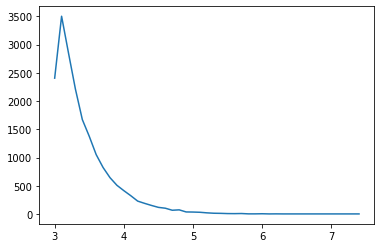

In [23]:
import matplotlib.pyplot as plt
plt.plot(
    *np.unique(cat.magnitude, return_counts=True)
)

In [9]:
ccc = pd.read_csv("../../forecasting/experiments/mcvar/data/201127_california_rounded_01.csv", index_col=0, parse_dates=["time"])

In [15]:
ts = dt.datetime(2017, 1, 1)
te = dt.datetime(2019, 1, 1)
mags = ccc.query("time>=@ts and time < @te").magnitude
with open('magnitudes.npy', 'wb') as f:
    np.save(f, mags)

In [64]:
ipip = pd.read_csv("ind_and_bg_probs.csv", index_col=0, parse_dates=["time"])

In [65]:
ipip["P_background"] + ipip["P_triggered"]

target_id
1197     1.0
1198     1.0
1199     1.0
1200     1.0
1201     1.0
        ... 
10541    1.0
10542    1.0
10563    1.0
10564    1.0
10582    1.0
Length: 3501, dtype: float64